In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



Columns detected: ['loss', 'sparse_categorical_accuracy', 'val_loss', 'val_sparse_categorical_accuracy']


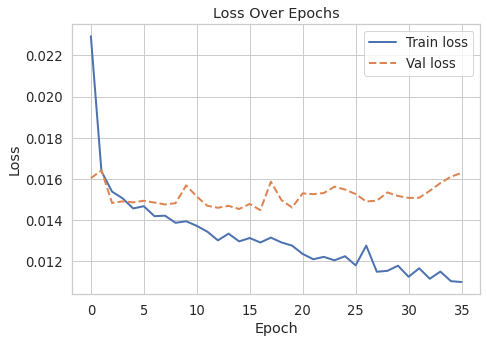

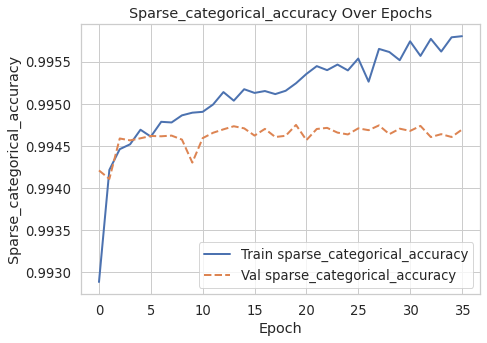

In [6]:

# --- CONFIG ---
CSV_PATH = "/home/jovyan/work/training-models/nepal/Nepal_b7_2025/v6/results/history.csv"   # change this to your filename

# --- STYLE ---
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams["figure.figsize"] = (7, 5)

# --- LOAD CSV ---
history = pd.read_csv(CSV_PATH)
print("Columns detected:", list(history.columns))

# --- AUTO-DETECT METRICS ---
metrics = {}
for col in history.columns:
    if col.startswith("val_"):
        base = col[4:]
        metrics.setdefault(base, {"train": None, "val": None})
        metrics[base]["val"] = col
    else:
        metrics.setdefault(col, {"train": None, "val": None})
        metrics[col]["train"] = col

# --- PLOT EACH METRIC ---
for metric, cols in metrics.items():
    train_col = cols["train"]
    val_col = cols["val"]

    plt.figure()

    if train_col in history.columns:
        plt.plot(history[train_col], label=f"Train {metric}", linewidth=2)

    if val_col in history.columns:
        plt.plot(history[val_col], label=f"Val {metric}", linestyle="--", linewidth=2)

    plt.title(f"{metric.capitalize()} Over Epochs")
    plt.xlabel("Epoch")
    plt.ylabel(metric.capitalize())
    plt.legend()
    plt.tight_layout()

    plt.show()    # <-- display instead of saving


In [4]:
import glob

len(glob.glob("/home/jovyan/work/training-models/nepal/Nepal_b7_2025/data/imgs_prepared_v4/train_chips/*"))

13398

In [5]:
import math

dataset_size =13398      # number of training samples
batch_size = 32
epochs = 1            # how many epochs you want to consider

steps_per_epoch = math.ceil(dataset_size / batch_size)
total_steps = steps_per_epoch * epochs

print("Steps per epoch:", steps_per_epoch)
print("Total steps:", total_steps)

Steps per epoch: 419
Total steps: 419
